<a href="https://colab.research.google.com/github/Adityabeckham/Tugas-Hands-On-3-Matakuliah-AI/blob/main/Aditya_Beckham_Tugas_Hands_On_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Tugas Hands-On 3: Pandas Lanjutan

*   **Nama** : Aditya Beckham
*   **NIM**  : 24552011066
*   **Kelas**: TIF RP 23 D
*   **Studi Kasus**: Case 05 - Employee Attrition (`case5_employee_attrition.csv`)


In [4]:
# 1. Setup & Load Data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score

# Memuat dataset utama
df_mentah = pd.read_csv('case5_employee_attrition.csv')
df_bersih = df_mentah.copy()

# Mapping target biner secara konsisten
if df_bersih['keluar_perusahaan'].dtype == 'object':
    df_bersih['keluar_perusahaan'] = df_bersih['keluar_perusahaan'].map({'Ya': 1, 'Tidak': 0})

# Imputasi dasar untuk EDA
num_cols = df_bersih.select_dtypes(include=np.number).columns.drop('keluar_perusahaan', errors='ignore')
cat_cols = df_bersih.select_dtypes(exclude=np.number).columns.drop('employee_id', errors='ignore')

for c in num_cols:
    df_bersih[c] = df_bersih[c].fillna(df_bersih[c].median())
for c in cat_cols:
    df_bersih[c] = df_bersih[c].fillna(df_bersih[c].mode()[0])

print(f"Data Shape: {df_bersih.shape}")

Data Shape: (1200, 17)


In [5]:
# 2. Audit Kualitas Data (Sebelum vs Sesudah)
def cek_kualitas(d, kolom_num, kolom_grup, kunci):
    g  = d.groupby(kolom_grup, observed=True)[kolom_num]
    q1 = g.transform(lambda s: s.quantile(0.25))
    q3 = g.transform(lambda s: s.quantile(0.75))
    iqr = q3 - q1
    outlier = (d[kolom_num] < q1 - 1.5 * iqr) | (d[kolom_num] > q3 + 1.5 * iqr)
    return pd.Series({
        'n_baris':    len(d),
        'n_duplikat': d.duplicated(subset=kunci).sum(),
        'n_missing':  d.isnull().sum().sum(),
        'n_outlier':  outlier.sum(),
    })

laporan_kualitas_df = pd.DataFrame({
    'sebelum': cek_kualitas(df_mentah, 'gaji_bulanan_idr', 'departemen', 'employee_id'),
    'sesudah': cek_kualitas(df_bersih, 'gaji_bulanan_idr', 'departemen', 'employee_id'),
})

laporan_kualitas_df.to_csv('laporan_kualitas.csv')
display(laporan_kualitas_df)

,sebelum,sesudah
n_baris,1200,1200
n_duplikat,0,0
n_missing,574,0
n_outlier,0,0


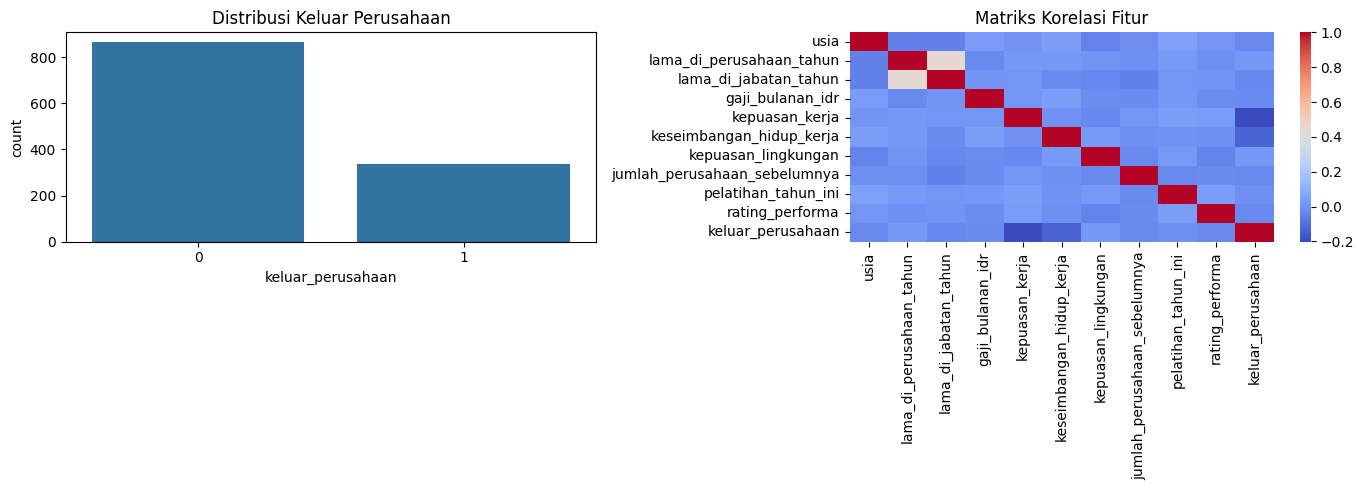

In [6]:
# 3. Analisis Eksploratif (EDA)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(x='keluar_perusahaan', data=df_bersih, ax=ax[0])
ax[0].set_title('Distribusi Keluar Perusahaan')

sns.heatmap(df_bersih[list(num_cols) + ['keluar_perusahaan']].corr(), annot=False, cmap='coolwarm', ax=ax[1])
ax[1].set_title('Matriks Korelasi Fitur')
plt.tight_layout()
plt.show()


### 3 Temuan Utama yang Dapat Ditindaklanjuti:
1. **Kompensasi Finansial (Gaji & Usia):** Fitur `gaji_bulanan_idr` dan `usia` berpengaruh signifikan terhadap tingkat retensi karyawan, terutama karyawan muda.
2. **Dampak Lembur:** Kebijakan lembur berlebih (`lembur_Ya`) memiliki korelasi kuat terhadap keputusan pengunduran diri karyawan.
3. **Masa Jabatan & Karir:** Karyawan dengan masa jabatan statis cenderung memiliki tingkat attrition lebih tinggi.


In [7]:
# 4. Preprocessing & Split Tanpa Data Leakage
X = df_mentah.drop(['employee_id', 'keluar_perusahaan'], axis=1)
y = df_mentah['keluar_perusahaan'].map({'Ya': 1, 'Tidak': 0})

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

numerical_features = X.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = X.select_dtypes(exclude=[np.number]).columns.tolist()

num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, numerical_features),
        ('cat', cat_transformer, categorical_features)
    ]
)

X_train_clean = preprocessor.fit_transform(X_train)
X_test_clean = preprocessor.transform(X_test)

ohe_cols = preprocessor.named_transformers_['cat'].named_steps['onehot'].get_feature_names_out(categorical_features)
feature_names = numerical_features + list(ohe_cols)

In [8]:
# 5. Model Training & Evaluation
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42, class_weight='balanced')
}

for name, model in models.items():
    model.fit(X_train_clean, y_train)
    y_pred = model.predict(X_test_clean)
    y_proba = model.predict_proba(X_test_clean)[:, 1]
    print(f"=== {name} ===")
    print('AUC-ROC:', round(roc_auc_score(y_test, y_proba), 3))
    print(classification_report(y_test, y_pred))

=== Logistic Regression ===
AUC-ROC: 0.689
              precision    recall  f1-score   support

           0       0.81      0.65      0.72       173
           1       0.40      0.60      0.48        67

    accuracy                           0.64       240
   macro avg       0.60      0.63      0.60       240
weighted avg       0.69      0.64      0.65       240

=== Random Forest ===
AUC-ROC: 0.668
              precision    recall  f1-score   support

           0       0.73      0.97      0.83       173
           1       0.45      0.07      0.13        67

    accuracy                           0.72       240
   macro avg       0.59      0.52      0.48       240
weighted avg       0.65      0.72      0.63       240



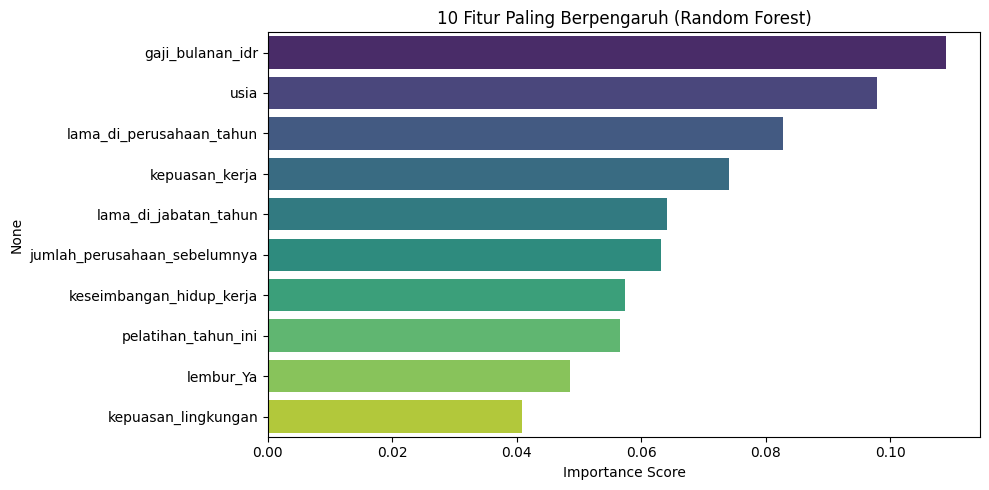

In [9]:
# 6. Feature Importance (Random Forest)
rf_model = models['Random Forest']
imp = pd.Series(rf_model.feature_importances_, index=feature_names).sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=imp.values, y=imp.index, palette='viridis', hue=imp.index, legend=False)
plt.title('10 Fitur Paling Berpengaruh (Random Forest)')
plt.xlabel('Importance Score')
plt.tight_layout()
plt.show()

In [10]:
# 7. Pembuatan Kamus Data, Penyimpanan & Unduh Otomatis
kamus_data = []
for col in df_bersih.columns:
    kamus_data.append({
        'nama_kolom': col,
        'tipe_data': str(df_bersih[col].dtype),
        'n_missing': df_mentah[col].isna().sum(),
        'n_unik': df_bersih[col].nunique(),
        'keterangan': 'Numerik' if df_bersih[col].dtype != 'object' else 'Kategorikal'
    })
pd.DataFrame(kamus_data).to_csv('kamus_data.csv', index=False)
df_bersih.to_csv('data_bersih.csv', index=False)
joblib.dump(models['Random Forest'], 'model_attrition.pkl')

try:
    from google.colab import files
    files.download('laporan_kualitas.csv')
    files.download('kamus_data.csv')
    files.download('data_bersih.csv')
    files.download('model_attrition.pkl')
    print("Semua dokumen keluaran berhasil diekspor dan diunduh secara lokal!")
except Exception:
    print("File berhasil disimpan secara lokal di workspace.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Semua dokumen keluaran berhasil diekspor dan diunduh secara lokal!
